# Volatility Dynamics 08 — jump arrivals as a point process

**VD 017.** Modules 03–07 showed that raw q99 *variance* events are explained by the volatility level. Module 08 studies **jumps**: returns extreme *relative to* causal local volatility, and asks whether they arrive as a Poisson process, follow the clock/volatility, or **self-excite** (Hawkes).

**Jump:** $\tilde r_t = r_t/s_a(\text{time of day})$ (smooth 2-harmonic clock, training days); $BV_t$ = **two-sided** jump-robust bipower over the hour before and after $t$ (pairs touching $t$ excluded); $z_t=|\tilde r_t|/\sqrt{BV_t}$; $J_t=\mathbf 1\{z_t>c\}$, **$c=4$** (sensitivity grid 3–5 reported, not used for the decision).

**Models** (5-min bars, $P(J=1)=1-e^{-\lambda}$):
(a) $\lambda=e^{\alpha_a}$ · (b) $\lambda=\exp(\alpha_a+\text{Fourier}_2+\gamma\log\sigma^{local})$ · (c) (b) $+\ \eta_s E^{self}+\eta_c E^{cross}$, exponential kernel, half-life profiled. Branching ratio $\rho=\eta_s+\eta_c(N-1)$.

**Pre-registered decision:** 5-fold blocked CV by day blocks. Self-excitation iff out-of-fold logLik/row (c)−(b) > 0 with day-bootstrap q2.5 > 0 and ≥ 50 scored jumps; same rule (b)−(a) for inhomogeneity. Chronological 70/30 holdout reported as secondary. Validated on synthetic data of this size: 0/8 false passes under a null with a common volatility factor and Student-t(4) diffusion; power ≈ 1/3 against a true $\rho=0.37$, with $\rho$ recovered (0.23–0.43). **A FAIL at this sample size is not evidence of absence.** Two-sided local volatility makes this an *explanatory* model (does a past jump raise the jump probability beyond local volatility?), not a real-time forecaster.

Inputs: `state_time`, `underlying`, `return_5m` only. Outputs: `08/`.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 300)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_vd_b_core as vb
from data_engineering.modeling import volatility_jump_hawkes as jh
START = os.getenv('VD8_START', '').strip() or None
END = os.getenv('VD8_END', '').strip() or None
ASSETS = [x.strip().upper() for x in os.getenv('VD8_ASSETS', '').split(',') if x.strip()]
N_BOOT = int(os.getenv('VD8_N_BOOT', str(jh.N_BOOT)))
N_BOOT_SENS = int(os.getenv('VD8_N_BOOT_SENS', '500'))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '08'
OUT.mkdir(parents=True, exist_ok=True)
print('Module 08', jh.VERSION)
print('selftest:', jh.selftest())


Module 08 0.1.0
selftest: {'kernel_recursion': True, 'jump_detection': True, 'hawkes_detected_when_present': True, 'no_false_hawkes_common_vol_t4_null': True, 'branching_ratio_recovered': 0.357}


rows 42,336 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | 2026-09-19 08:00:00+00:00 -> 2026-10-10 07:55:00+00:00
assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | bars 6048 | holdout starts 2026-10-05 00:00:00+00:00


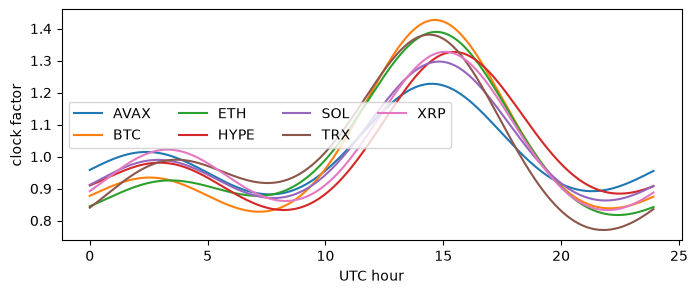

In [2]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

def load_frame(columns, start=None, end=None, assets=None):
    cols = list(dict.fromkeys(['state_time', 'underlying', 'return_5m'] + list(columns)))
    where = []
    if start:
        ts = pd.Timestamp(start)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
    if end:
        ts = pd.Timestamp(end)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time < TIMESTAMPTZ '{(ts + pd.Timedelta(days=1)).isoformat()}'")
    if assets:
        where.append('underlying IN (' + ','.join(repr(x) for x in assets) + ')')
    sql = ('SELECT ' + ', '.join(qident(c) for c in cols) + ' FROM time_series_feature_state'
           + ('' if not where else ' WHERE ' + ' AND '.join(where)) + ' ORDER BY underlying, state_time')
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        df = con.execute(sql).df()
    finally:
        con.close()
    if df.empty:
        raise RuntimeError('No rows found.')
    df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
    if df.duplicated(['underlying', 'state_time']).any():
        raise RuntimeError('Duplicate asset/timestamp rows.')
    print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())} | {df.state_time.min()} -> {df.state_time.max()}')
    return df.reset_index(drop=True)

def schema_columns():
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        return con.execute('DESCRIBE time_series_feature_state').df()
    finally:
        con.close()

df = load_frame([], START, END, ASSETS)
grid = vb.build_grid(df)
panel = jh.build_panel(grid)
train_rows, test_rows, test_first_day = jh.chronological_rows(panel)
print('assets', panel.assets, '| bars', panel.T, '| holdout starts', pd.Timestamp(test_first_day * 288 * vb.BAR_NS, tz='UTC'))
S = jh.clock_factors(panel, train_rows)
Z, BV = jh.jump_statistics(panel, S)
C = jh.baseline_covariates(panel, S, BV)
fig, ax = plt.subplots(figsize=(8, 3))
for a, name in enumerate(panel.assets):
    ax.plot(np.arange(288) / 12, S[:, a], label=name)
ax.set_xlabel('UTC hour'); ax.set_ylabel('clock factor'); ax.legend(ncol=4); plt.show()


,underlying,valid_bars,jumps,jump_rate_per_day,gaussian_expected_jumps,excess_vs_gaussian,daily_count_var_to_mean
0,AVAX,5151,29,1.621,0.326,88.881,1.559
1,BTC,5151,38,2.125,0.326,116.465,0.493
2,ETH,5151,33,1.845,0.326,101.141,0.719
3,HYPE,5151,15,0.839,0.326,45.973,1.105
4,SOL,5151,27,1.510,0.326,82.752,0.489
5,TRX,5149,75,4.195,0.326,229.955,0.782
6,XRP,5151,28,1.566,0.326,85.817,1.158


,assets_jumping_same_bar,n_bars
0,1.0,136
1,2.0,12
2,3.0,10
3,4.0,7
4,5.0,3
5,6.0,2


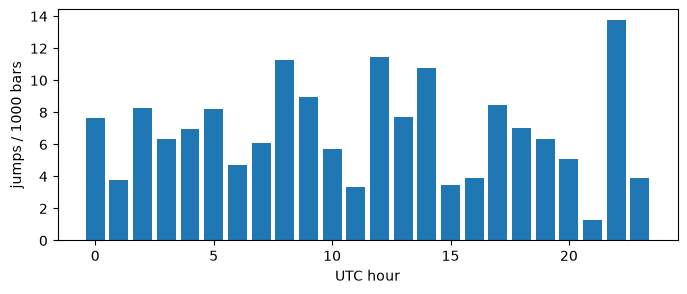

z tail shares: {3.0: 0.019248370545000695, 3.5: 0.011121897101650256, 4.0: 0.006795174039661628, 4.5: 0.004271252253501594, 5.0: 0.0028290112328387186}


In [3]:
J, valid = jh.jump_indicator(Z, jh.PRIMARY_C)
per_asset, by_hour, cojump = jh.jump_descriptives(panel, J, valid, Z, jh.PRIMARY_C)
display(per_asset.round(3)); display(cojump)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(by_hour.hour_utc, by_hour.jump_rate_per_1000_bars); ax.set_xlabel('UTC hour'); ax.set_ylabel('jumps / 1000 bars'); plt.show()
z = Z[np.isfinite(Z)]
print('z tail shares:', {c: float(np.mean(z > c)) for c in jh.C_GRID})


primary analysis 11s
{
  "event_set": "jumps_c4",
  "n_events_full_sample": 245,
  "hawkes_half_life_min_full_sample": 5.0,
  "eta_self": 0.004312248979488068,
  "eta_self_approx_se": 0.012322106078275179,
  "eta_cross": 0.007100544615513132,
  "eta_cross_approx_se": 0.003787166158740929,
  "branching_ratio": 0.046915516672566854,
  "branching_ratio_across_cv_folds": [
    0.0656,
    0.0443,
    0.07,
    0.0522,
    0.0
  ],
  "gamma_log_localvol_b": -0.5940449890849897,
  "primary_blocked_cv": {
    "rule": "logLik/row delta > 0 with day-block bootstrap q2.5 > 0 and >= 50 scored jumps",
    "n_scored_jumps": 245,
    "self_excitation_c_vs_b": {
      "delta_loglik_per_row": -0.00016200806658187434,
      "boot_q025": -0.0003155112302098163,
      "boot_q975": -1.4795262065490204e-05,
      "status": "FAIL"
    },
    "inhomogeneity_b_vs_a": {
      "delta_loglik_per_row": -0.00018977524544013858,
      "boot_q025": -0.0006617632611558541,
      "boot_q975": 0.0002766492172061787,
  

,model,oof_rows,oof_events,oof_loglik_per_row
0,a_homogeneous,36055,245,-0.040181
1,b_inhomogeneous,36055,245,-0.040371
2,c_hawkes,36055,245,-0.040533


,comparison,delta_loglik_per_row,boot_q025,boot_q975,n_days
0,c_hawkes - b_inhomogeneous,-0.000162,-0.000316,-0.000015,20
1,b_inhomogeneous - a_homogeneous,-0.000190,-0.000662,0.000277,20


,fold,first_day,last_day,test_rows,test_events,half_life_min,eta_self,eta_cross,branching_ratio
0,0,20717,20720,6923,42,5.0,0.0064,0.0099,0.0656
1,1,20721,20724,7875,58,5.0,0.0017,0.0071,0.0443
2,2,20725,20728,7607,57,5.0,0.0032,0.0111,0.0700
3,3,20729,20732,7462,45,5.0,0.0091,0.0072,0.0522
4,4,20733,20736,6188,43,5.0,0.0000,0.0000,0.0000


,comparison,delta_loglik_per_row,boot_q025,boot_q975,n_test_days
0,c_hawkes - b_inhomogeneous,-0.000008,-0.000018,0.000004,6
1,b_inhomogeneous - a_homogeneous,0.000009,-0.001090,0.000871,6
2,c_hawkes - a_homogeneous,0.000001,-0.001096,0.000887,6


,model,fit,n_intervals,ks_D,ks_p,mean_tau,cv_tau
0,a_homogeneous,full_sample_in_sample,238,0.0510,0.5543,0.9639,0.8861
1,b_inhomogeneous,full_sample_in_sample,238,0.0581,0.3884,0.9693,0.9543
2,c_hawkes,full_sample_in_sample,238,0.0560,0.4339,0.9707,0.9562


,model,parameter,estimate,approx_se
0,a,alpha_AVAX,-5.1768,0.1857
1,a,alpha_BTC,-4.9057,0.1622
2,a,alpha_ETH,-5.0472,0.1741
3,a,alpha_HYPE,-5.8374,0.2582
4,a,alpha_SOL,-5.2485,0.1925
5,a,alpha_TRX,-4.2217,0.1155
6,a,alpha_XRP,-5.2120,0.1890
7,b,alpha_AVAX,-5.2165,0.1865
8,b,alpha_BTC,-4.9969,0.1656
9,b,alpha_ETH,-5.1274,0.1765


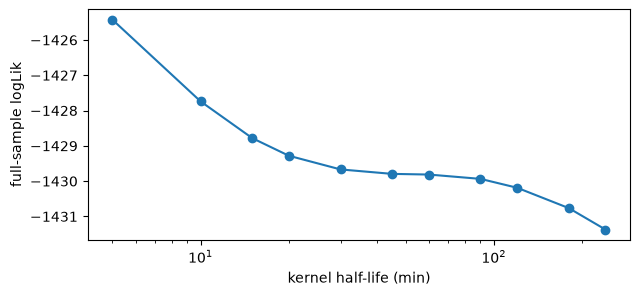

In [4]:
t0 = time.time()
primary = jh.analyse(panel, J, valid, C, train_rows, test_rows, n_boot=N_BOOT, label='jumps_c4')
print(f'primary analysis {time.time()-t0:.0f}s')
print(json.dumps(primary['summary'], indent=2, default=float))
display(primary['cv_scores']); display(primary['cv_boot'].round(6)); display(primary['cv_folds'].round(4))
display(primary['holdout_boot'].round(6)); display(primary['gof'].round(4))
display(primary['params'].round(4))
prof = primary['profile']
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(prof.half_life_min, prof.train_loglik, marker='o'); ax.set_xscale('log')
ax.set_xlabel('kernel half-life (min)'); ax.set_ylabel('full-sample logLik'); plt.show()


In [5]:
sens_rows = []
for c in jh.C_GRID:
    Jc, vc = jh.jump_indicator(Z, c)
    r = jh.analyse(panel, Jc, vc, C, train_rows, test_rows, n_boot=N_BOOT_SENS, label=f'jumps_c{c}')
    s = r['summary']
    sens_rows.append({
        'c': c, 'is_primary': c == jh.PRIMARY_C, 'n_jumps': s['n_events_full_sample'],
        'branching_ratio': s['branching_ratio'], 'half_life_min': s['hawkes_half_life_min_full_sample'],
        'eta_self': s['eta_self'], 'eta_cross': s['eta_cross'],
        'cv_self_excitation': s['primary_blocked_cv']['self_excitation_c_vs_b']['status'],
        'cv_delta_c_vs_b': s['primary_blocked_cv']['self_excitation_c_vs_b']['delta_loglik_per_row'],
        'cv_inhomogeneity': s['primary_blocked_cv']['inhomogeneity_b_vs_a']['status'],
    })
sensitivity = pd.DataFrame(sens_rows)
display(sensitivity.round(5))


,c,is_primary,n_jumps,branching_ratio,half_life_min,eta_self,eta_cross,cv_self_excitation,cv_delta_c_vs_b,cv_inhomogeneity
0,3.0,False,694,0.05061,5.0,0.00979,0.00680,FAIL,0.00020,FAIL
1,3.5,False,401,0.04610,5.0,0.00000,0.00768,FAIL,0.00000,FAIL
2,4.0,True,245,0.04692,5.0,0.00431,0.00710,FAIL,-0.00016,FAIL
3,4.5,False,154,0.08103,5.0,0.00196,0.01318,FAIL,-0.00003,FAIL
4,5.0,False,102,0.03568,5.0,0.00206,0.00560,FAIL,-0.00011,FAIL


In [6]:
Jq, vq = jh.q99_indicator(panel)
secondary_q99 = jh.analyse(panel, Jq, vq, C, train_rows, test_rows, n_boot=N_BOOT_SENS, label='raw_q99_onsets')
print(json.dumps(secondary_q99['summary'], indent=2, default=float))


{
  "event_set": "raw_q99_onsets",
  "n_events_full_sample": 331,
  "hawkes_half_life_min_full_sample": 5.0,
  "eta_self": 0.0,
  "eta_self_approx_se": 0.013679398584123275,
  "eta_cross": 0.01902580816180976,
  "eta_cross_approx_se": 0.004910638579325578,
  "branching_ratio": 0.11415484897085856,
  "branching_ratio_across_cv_folds": [
    0.1394,
    0.087,
    0.139,
    0.1191,
    0.1077
  ],
  "gamma_log_localvol_b": 2.3608246220013447,
  "primary_blocked_cv": {
    "rule": "logLik/row delta > 0 with day-block bootstrap q2.5 > 0 and >= 50 scored jumps",
    "n_scored_jumps": 331,
    "self_excitation_c_vs_b": {
      "delta_loglik_per_row": 0.0003080783159599512,
      "boot_q025": -0.00017892103796252724,
      "boot_q975": 0.0008559801148793723,
      "status": "FAIL"
    },
    "inhomogeneity_b_vs_a": {
      "delta_loglik_per_row": 0.006712026561035593,
      "boot_q025": 0.004567674536878379,
      "boot_q975": 0.008956684472158345,
      "status": "PASS"
    }
  },
  "second

In [7]:
per_asset.to_csv(OUT / '08_jumps_per_asset.csv', index=False)
by_hour.to_csv(OUT / '08_jump_rate_by_hour.csv', index=False)
cojump.to_csv(OUT / '08_cojump_counts.csv', index=False)
pd.DataFrame(S, columns=panel.assets).assign(slot=np.arange(288)).to_csv(OUT / '08_clock_factors.csv', index=False)
for k in ['cv_scores', 'cv_boot', 'cv_folds', 'holdout_scores', 'holdout_boot', 'gof', 'params', 'profile']:
    primary[k].to_csv(OUT / f'08_primary_{k}.csv', index=False)
for k in ['cv_boot', 'cv_folds', 'gof', 'params']:
    secondary_q99[k].to_csv(OUT / f'08_q99_{k}.csv', index=False)
sensitivity.to_csv(OUT / '08_c_sensitivity.csv', index=False)
(OUT / '08_decision.json').write_text(json.dumps({'primary_c4': primary['summary'], 'secondary_raw_q99': secondary_q99['summary']}, indent=2, default=float))
meta = {
    'version': jh.VERSION, 'module': '08_jump_point_process', 'primary_c': jh.PRIMARY_C, 'c_grid': list(jh.C_GRID),
    'local_vol': 'two-sided bipower, +/- %d bars, pairs touching t excluded' % jh.LOCAL_HALF_WINDOW, 'half_life_grid_bars': list(jh.HALF_LIFE_GRID_BARS),
    'decision_primary': 'blocked 5-fold CV by day; delta logLik/row (c)-(b) > 0 with day-bootstrap q2.5 > 0, >= 50 jumps',
    'holdout_first_day': str(pd.Timestamp(test_first_day * 288 * vb.BAR_NS, tz='UTC')), 'n_boot': N_BOOT,
    'first_time': str(df.state_time.min()), 'last_time': str(df.state_time.max()), 'n_rows': int(len(df)),
}
(OUT / '08_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote', OUT)


wrote D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\08
